# IDX Exchange Data Science Internship - Week Eight - Evaluation Expansion

* Compute metrics beyond R²: MAPE and MdAPE.
* Summarize insights (e.g., which price bands perform better).

---------

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb
from xgboost import XGBRegressor

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

During the past few weeks we have been constructing increasingly more effective models for predicting the ClosePrice of MLS properties. So far we have used Linear Regression, Decision Trees, Random Forests, and XGBoost to achieve this end. However, it's a good idea to look more deeply into what we deem to be an "effective" model. For this reason, this notebook will be dedicated to gaining a more thorough understanding of these models' performance. This will involve investigating feature importance, plotting actual vs. prediction difference, and analyzing model performance for different price bands and locations.

## Import Data

In [2]:
# Create functions for quickly evaluating the models

def median_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.median(np.abs((y_true - y_pred) / y_true))

def metrics(y_true, y_pred, logged=True):
    # Note: you have to undo the log transform on ClosePrice by using np.exp()
    if logged == True:
        y_true = np.exp(y_true)
        y_pred = np.exp(y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    mdape = median_absolute_percentage_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    return r2, mape * 100, mdape * 100, mae

def metric_df(r2_train, mape_train, mdape_train, mae_train,
              r2_val, mape_val, mdape_val, mae_val,
              r2_test, mape_test, mdape_test, mae_test):
    data = {"r2": [r2_train, r2_val, r2_test],
            "MAPE": [mape_train, mape_val, mape_test],
            "MdAPE": [mdape_train, mdape_val, mdape_test],
            "MAE": [f"${round(mae_train, 2)}", f"${round(mae_val, 2)}", f"${round(mae_test, 2)}"]}
    df = pd.DataFrame(data)
    df.index = ["Train Set", "Validation Set", "Test Set"]
    return df

In [3]:
# Read in the training and test sets created in week six

train_and_val = pd.read_csv("feat_eng_train.csv")
testing = pd.read_csv("feat_eng_test.csv")

# Carve out training and validation sets
training = train_and_val[~(train_and_val["PropertyMonth"] == "2026-03-01")]
validation = train_and_val[train_and_val["PropertyMonth"] == "2026-03-01"]

print(train_and_val.shape, training.shape, validation.shape)

(265296, 153) (255004, 153) (10292, 153)


In [4]:
# These columns have performed well with our models in previous weeks, so they will be selected here

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "DistrictName_elem_enc", "DistrictName_unif_enc", "DistrictName_high_enc",
            "BedBathRatio", "PropertyAge",  
            'EnrollTotal_high', 'EnrollCharter_high','EnrollNonCharter_high', # High school enrollment counts
            'EnrollTotal_elem','EnrollCharter_elem','EnrollNonCharter_elem', # Elementary school enrollment counts
            'EnrollTotal_unif','EnrollCharter_unif','EnrollNonCharter_unif', # Unified shcool district enrollment counts
            'ELpct_high','ELpct_elem','ELpct_unif', # English-learning student percent
            'FOSpct_high','FOSpct_elem','FOSpct_unif', # Foster student percent
            'HOMpct_high','HOMpct_elem','HOMpct_unif', # Homeless student percent
            'SEDpct_high', 'SEDpct_elem','SEDpct_unif'] # Socioeconomically disadvantaged student percent

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

## Evaluate Each Model

To get a baseline idea of each model's performance, let's run all four types (Linear Regression, Decision Tree, Random Forest, XGBoost) on the same dataset. Note that hyperparameter tuning was performed in previous weeks, and those same hyperparameters have been repeated here.

### Linear Regression

In [5]:
lin_reg = LinearRegression()
lin_reg.fit(x_train, y_train)

pred_train_lr = lin_reg.predict(x_train)
pred_val_lr = lin_reg.predict(x_val)
pred_test_lr = lin_reg.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train_lr)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val_lr)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test_lr)

lin_reg_model = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
lin_reg_model

,r2,MAPE,MdAPE,MAE
Train Set,0.840598,13.245447,10.116074,$149263.9
Validation Set,0.830025,13.585066,10.550619,$155254.11
Test Set,0.852009,12.855074,9.966950,$151505.62


### Decision Tree

In [6]:
dec_tree = DecisionTreeRegressor(max_depth=13, random_state=42)
dec_tree.fit(x_train, y_train)

pred_train_dt = dec_tree.predict(x_train)
pred_val_dt = dec_tree.predict(x_val)
pred_test_dt = dec_tree.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train_dt)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val_dt)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test_dt)

dec_tree_model = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
dec_tree_model

,r2,MAPE,MdAPE,MAE
Train Set,0.897921,10.430970,7.610139,$118241.69
Validation Set,0.845526,12.390981,8.900147,$143358.89
Test Set,0.866418,11.772792,8.429331,$140350.81


### Random Forest

In [7]:
rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train_rf = rf.predict(x_train)
pred_val_rf = rf.predict(x_val)
pred_test_rf = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train_rf)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val_rf)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test_rf)

rand_forest_model = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rand_forest_model

,r2,MAPE,MdAPE,MAE
Train Set,0.968298,5.977990,4.532435,$67674.49
Validation Set,0.889294,10.316497,7.323497,$120658.05
Test Set,0.905755,9.700517,6.798659,$116378.64


### XGBoost

In [8]:
xgboo = xgb.XGBRegressor(n_estimators=900, learning_rate=0.05, max_depth=10, random_state=42)
xgboo.fit(x_train, y_train)

pred_train_xgb = xgboo.predict(x_train)
pred_val_xgb = xgboo.predict(x_val)
pred_test_xgb = xgboo.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train_xgb)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val_xgb)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test_xgb)

xgboost_model = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
xgboost_model

,r2,MAPE,MdAPE,MAE
Train Set,0.973753,5.576506,4.154534,$61715.59
Validation Set,0.911776,9.270704,6.603575,$107709.21
Test Set,0.919499,8.893307,6.240518,$106460.18


### Metrics Summary

In [9]:
metrics_summary = pd.DataFrame()

row1 = lin_reg_model.iloc[[2]]
row2 = dec_tree_model.iloc[[2]]
row3 = rand_forest_model.iloc[[2]]
row4 = xgboost_model.iloc[[2]]

metrics_summary = pd.concat([metrics_summary, row1], ignore_index=True)
metrics_summary = pd.concat([metrics_summary, row2], ignore_index=True)
metrics_summary = pd.concat([metrics_summary, row3], ignore_index=True)
metrics_summary = pd.concat([metrics_summary, row4], ignore_index=True)
metrics_summary.index = ["Linear Regression", "Decision Tree", "Random Forest", "XGBoost"]
metrics_summary.columns = ["Test r2", "Test MAPE", "Test MdAPE", "Test MAE"]

metrics_summary

,Test r2,Test MAPE,Test MdAPE,Test MAE
Linear Regression,0.852009,12.855074,9.966950,$151505.62
Decision Tree,0.866418,11.772792,8.429331,$140350.81
Random Forest,0.905755,9.700517,6.798659,$116378.64
XGBoost,0.919499,8.893307,6.240518,$106460.18


In [10]:
metrics_summary.to_csv("metrics_summary.csv", index=False)

As we found in previous weeks, performance increases on all metrics as we use more advanced models. However, these numbers are not the full story. It's possible that the models perform very well for predicting the prices of relatively cheap homes, but not luxury homes. Or that they're good at predicting Bay Area prices but not Central Valley ones. We wouldn't be able to determine those faults from these numbers alone, which is why a more thorough investigation is needed.

## Investigate Feature Importance

A big question in machine learning is how our models are making the decisions that they do. Feature importance is a way that we can get some insight on this. Feature importance measures how much each feature contributes to the model's prediction accuracy. We can get the feature importance from each tree model to see what is driving the model's decisions. This will give us valuable information about what features are most relevant to predicting housing prices. 

Note that feature importance will work for Decision Trees, Random Forests, and XGBoost as tree-based models, but will not work for Linear Regression. In the case of Linear Regression, we can employ a similar concept: analyzing its coeffecients. Regression coefficients for each feature tell us the strength of the relationship between that feature and the target variable. The bigger the coefficient, the stronger its relationship with the target variable, and therefore, the more predictive power it has. Coeffecients can be postive or negative, with positive values meaning that both the feature and the target increase/decrease together, while negative values imply an inverse relationship: as the feature increases, the target decreases (or vice versa). Both directions are useful for predictions.

### Linear Regression

In [11]:
# To analyze the coefficients of a linear regression model, we have to scale the features first.
# Re-run the linear regression model with scaled features

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(x_train, y_train)

coefficients = model.named_steps["linearregression"].coef_
lin_reg_import = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": abs(coefficients),
    "Relationship": ["Positive" if coeff > 0 else "Negative" for coeff in coefficients]})

lin_reg_import.sort_values(by="Importance", ascending=False).reset_index(drop=True).head(10)

,Feature,Importance,Relationship
0,PostalCode_enc,0.263142,Positive
1,LivingAreaLog,0.162829,Positive
2,EnrollCharter_unif,0.120927,Negative
3,BathroomsTotalInteger,0.101201,Positive
4,EnrollNonCharter_unif,0.088091,Positive
5,Longitude,0.078420,Negative
6,Latitude,0.063115,Negative
7,DistrictName_unif_enc,0.059967,Positive
8,DistrictName_elem_enc,0.052114,Positive
9,BedroomsTotal,0.050355,Negative


These are the largest coefficients for the Linear Regression model. From the top value, we can see that PostalCode has a large sway in predicting ClosePrice. Looking at the next few features tells us that LivingArea has a strong positive relationship with ClosePrice, and that EnrollCharter (number of students enrolled in a public school) has a fairly strong negative relationship with ClosePrice. These results make intuitive sense. We would expect that the greater the size of a house, the greater its price. Likewise, PostalCode and EnrollCharter encode location-based economic information, which can have a huge impact on housing prices.

### Decision Tree

In [12]:
feature_names = x_train.columns
importances = dec_tree.feature_importances_

dec_tree_import = pd.DataFrame({"Feature": feature_names, "Importance": importances})

dec_tree_import.sort_values(by="Importance", ascending=False).reset_index(drop=True).head(10)

,Feature,Importance
0,PostalCode_enc,0.781014
1,LivingAreaLog,0.144962
2,LotSizeSquareFeetLog,0.011045
3,CountyOrParish_enc,0.008731
4,City_enc,0.007430
5,Longitude,0.006369
6,AssociationFeeLog,0.006194
7,PropertyAge,0.004611
8,Latitude,0.004466
9,DistrictName_unif_enc,0.004303


As a reminder, these results represent different ideas than the linear regression numbers above. These are feature importances, not regression coefficients. Despite this, we see similar results. PostalCode again comes up as the feature with most sway, and by a very long shot this time! It's very true that location has a big impact on prices, so this is not surprising. The next two most important features are LivingArea and LotSizeSquareFeet, which both refer to the size of the property.

### Random Forest

In [13]:
feature_names = x_train.columns
importances = rf.feature_importances_

rf_import = pd.DataFrame({"Feature": feature_names, "Importance": importances})

rf_import.sort_values(by="Importance", ascending=False).reset_index(drop=True).head(10)

,Feature,Importance
0,PostalCode_enc,0.737028
1,LivingAreaLog,0.140055
2,LotSizeSquareFeetLog,0.016154
3,Longitude,0.010941
4,City_enc,0.010913
5,CountyOrParish_enc,0.009862
6,Latitude,0.008646
7,PropertyAge,0.008042
8,AssociationFeeLog,0.006880
9,ListOfficeName_enc,0.006792


In the top three most important values, we see the same patterns as in the Decision Tree. Likewise, the subsequent top ten most important features remain mostly the same, though the order changes a bit. Most of these encode location (City, County, etc.). Though it's interesting to see AssociationFee among the top ten. It seems that HOA membership influences ClosePrice to a significant degree.

### XGBoost

In [14]:
importances = xgboo.feature_importances_

xgb_import = pd.DataFrame({"Feature": feature_names, "Importance": importances})
xgb_import.sort_values(by="Importance", ascending=False).reset_index(drop=True).head(10)

,Feature,Importance
0,PostalCode_enc,0.638569
1,LivingAreaLog,0.054239
2,BathroomsTotalInteger,0.019228
3,FOSpct_high,0.019177
4,City_enc,0.013525
5,CountyOrParish_enc,0.012446
6,AssociationFeeLog,0.009564
7,EnrollNonCharter_unif,0.009398
8,EnrollCharter_high,0.009048
9,EnrollTotal_high,0.008596


Once again, PostalCode and LivingArea are the top most important features. However, the importance of features in the XGBoost model differ significantly from there. BathroomsTotal becomes a key feature, as well as some demographic information, such as percentage of foster-care students and public/private school enrollment counts.

### Feature Importance Summary

For every model, the two most predictive features were PostalCode and LivingArea. Furthermore, in most cases PostalCode was the most important feature by a very wide margin. This affirms the famous saying "Location, Location, Location" in regards to real estate, which claims that the most important consideration for a property's value is its location. It is encouraging that our models agree with this notion.

## Plot Predicted vs. Actual

In this section, we will plot our predicted values of ClosePrice against the real ones for each model. If our predictions are generally accurate, the points will be clustered around the central diagonal line, representing a perfect one-to-one prediction. If our predictions are innacurate, they will be scattered further from this central line. This kind of plot can be a helpful visualization of where the most error occurs in our model.

In [15]:
lin_reg_data = pd.DataFrame({"Actual": np.exp(y_test), "Predicted": np.exp(pred_test_lr)})
dec_tree_data = pd.DataFrame({"Actual": np.exp(y_test), "Predicted": np.exp(pred_test_dt)})
rand_forest_data = pd.DataFrame({"Actual": np.exp(y_test), "Predicted": np.exp(pred_test_rf)})
xgb_data = pd.DataFrame({"Actual": np.exp(y_test), "Predicted": np.exp(pred_test_xgb)})

Text(0.5, 1.0, 'Actual vs. Predicted ClosePrice (XGBoost)')

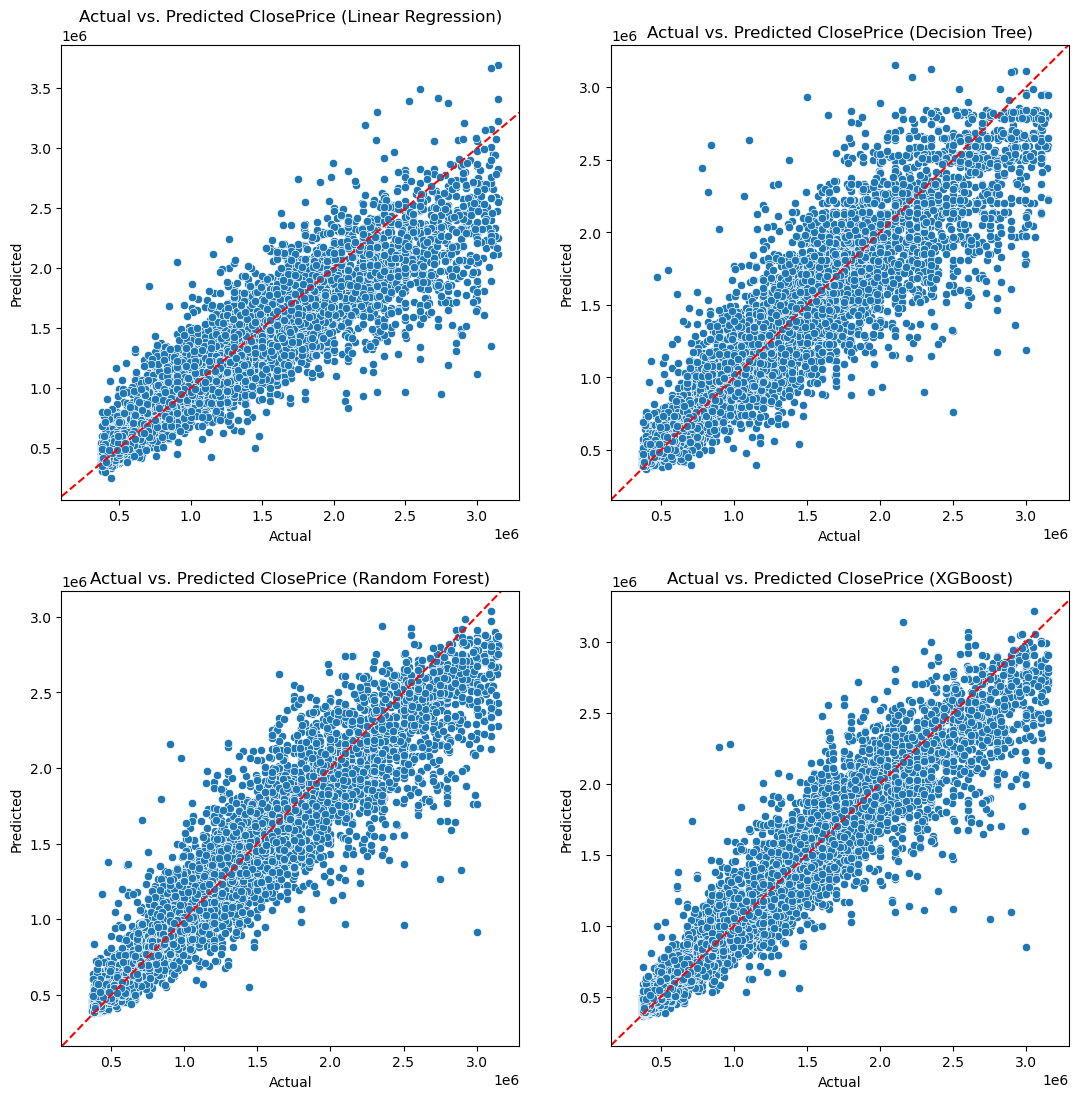

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 13))

sns.scatterplot(data=lin_reg_data, x="Actual", y="Predicted", ax=axes[0, 0])
axes[0,0].axline((240000,240000), slope=1, color='red', linestyle='--', linewidth=1.5)
axes[0,0].set_title("Actual vs. Predicted ClosePrice (Linear Regression)")

sns.scatterplot(data=dec_tree_data, x="Actual", y="Predicted", ax=axes[0,1])
axes[0,1].axline((300000,300000), slope=1, color='red', linestyle='--', linewidth=1.5)
axes[0,1].set_title("Actual vs. Predicted ClosePrice (Decision Tree)")

sns.scatterplot(data=rand_forest_data, x="Actual", y="Predicted", ax=axes[1,0])
axes[1,0].axline((300000,300000), slope=1, color='red', linestyle='--', linewidth=1.5)
axes[1,0].set_title("Actual vs. Predicted ClosePrice (Random Forest)")

sns.scatterplot(data=xgb_data, x="Actual", y="Predicted", ax=axes[1,1])
axes[1,1].axline((300000,300000), slope=1, color='red', linestyle='--', linewidth=1.5)
axes[1,1].set_title("Actual vs. Predicted ClosePrice (XGBoost)")

Points that fall below the red line represent our model under-predicting (the value of ClosePrice was higher than what the model predicted). Points that are higher than the red line represent the model over-predicting (the value of ClosePrice was lower than what the model predicted). From these graphs, we can see that every model has a tendency to under-predict, rather than over-predict. This happens particularly where the line is closest to the top right corner, which tells us that **the most errors in our models occur when they under-predict very expensive ClosePrices**. We can also see the improvement of each model in the graphs. As the model gets more advanced, the points become tighter around the central line, representing more accurate predictions.

## Analyze Price Band Performance

Our primary finding from the above section was that our models' performance suffers when they try to predict the price of expensive houses. Let's investigate that discovery further and examine how our models perform on different ranges of ClosePrice. These ranges will be divided into four different price bands, decided by percentiles of ClosePrice.

Note that performance in this section will be decided only by MAPE and MdAPE, instead of the usual r2, MAPE, MdAPE, and MAE. MAE is unhelpful for this section because we are working with different price bands. An error of \\$100,000 means a lot for a \\$600,000 home, but means little for a \$1,000,000 home. Thus, MAE is a misleading metric in this case, as we can always expect MAE to be smaller for smaller price bands and larger for larger price bands. Likewise, r2 scores will not be used because it is very sensitive to large error values when using a small dataset. Since there are only about 3000 datapoints for each price band, the r2 score will likely become too skewed by a small number of errors to be informative.

In [17]:
# Find the 0.25, 0.5, 0.75, and 1 percentiles of ClosePrice

sample_bins = [0, np.exp(y_train).quantile(0.25), np.exp(y_train).quantile(0.5), np.exp(y_train).quantile(0.75), np.exp(y_train).quantile(1)]
sample_bins

[0,
 np.float64(649999.9999999998),
 np.float64(890000.0000000006),
 np.float64(1350000.0000000002),
 np.float64(3156639.9999999963)]

In [18]:
# Manually convert these into integers
# Easier to read version: 0 -- 650,000 -- 890,000 -- 1,350,000 - 3,156,640

bins = [0, 650000, 890000, 1350000, 3156640] 
labels = ["<$650K", "\$650K-$890K", "\$890K-$1.35M", "$1.35M+"]

### Linear Regression

In [19]:
lin_reg_data["PriceBand"] = pd.cut(lin_reg_data["Actual"], bins=bins, labels=labels)

results_lr = []

for label, group in lin_reg_data.groupby("PriceBand", observed=True):
    r2_test, mape_test, mdape_test, mae_test = metrics(group["Actual"], group["Predicted"], False)
    num_props = len(group)
    results_lr.append([mape_test, mdape_test, num_props])

lr_bands_df = pd.DataFrame(results_lr, index=labels)
lr_bands_df.columns = ["Test MAPE", "Test MdAPE", "Num Properties"]
lr_bands_df

,Test MAPE,Test MdAPE,Num Properties
<$650K,12.482320,8.426422,2712
\$650K-$890K,12.164436,9.184632,2613
\$890K-$1.35M,12.324362,9.646259,2773
$1.35M+,14.183204,12.082946,3228


### Decision Tree

In [20]:
dec_tree_data["PriceBand"] = pd.cut(dec_tree_data["Actual"], bins=bins, labels=labels)

results_dt = []

for label, group in dec_tree_data.groupby("PriceBand", observed=True):
    r2_test, mape_test, mdape_test, mae_test = metrics(group["Actual"], group["Predicted"], False)
    num_props = len(group)
    results_dt.append([mape_test, mdape_test, num_props])

dt_bands_df = pd.DataFrame(results_dt, index=labels)
dt_bands_df.columns = ["Test MAPE", "Test MdAPE", "Num Properties"]
dt_bands_df

,Test MAPE,Test MdAPE,Num Properties
<$650K,10.551164,6.554594,2712
\$650K-$890K,10.031575,6.640491,2613
\$890K-$1.35M,12.484620,9.551150,2773
$1.35M+,13.597129,11.193179,3228


### Random Forest

In [21]:
rand_forest_data["PriceBand"] = pd.cut(rand_forest_data["Actual"], bins=bins, labels=labels)

results_rf = []

for label, group in rand_forest_data.groupby("PriceBand", observed=True):
    r2_test, mape_test, mdape_test, mae_test = metrics(group["Actual"], group["Predicted"], False)
    num_props = len(group)
    results_rf.append([mape_test, mdape_test, num_props])

rf_bands_df = pd.DataFrame(results_rf, index=labels)
rf_bands_df.columns = ["Test MAPE", "Test MdAPE", "Num Properties"]
rf_bands_df

,Test MAPE,Test MdAPE,Num Properties
<$650K,8.889709,5.044932,2712
\$650K-$890K,8.019774,5.341180,2613
\$890K-$1.35M,10.195895,7.530796,2773
$1.35M+,11.316691,9.321443,3228


### XGBoost

In [22]:
xgb_data["PriceBand"] = pd.cut(xgb_data["Actual"], bins=bins, labels=labels)

results_xgb = []

for label, group in xgb_data.groupby("PriceBand", observed=True):
    r2_test, mape_test, mdape_test, mae_test = metrics(group["Actual"], group["Predicted"], False)
    num_props = len(group)
    results_xgb.append([mape_test, mdape_test, num_props])

xgb_bands_df = pd.DataFrame(results_xgb, index=labels)
xgb_bands_df.columns = ["Test MAPE", "Test MdAPE", "Num Properties"]
xgb_bands_df

,Test MAPE,Test MdAPE,Num Properties
<$650K,7.992131,4.695446,2712
\$650K-$890K,7.514709,5.011109,2613
\$890K-$1.35M,9.372293,6.945837,2773
$1.35M+,10.354906,8.306254,3228


### Price Band Summary

#### Price Band MAPE for Different Models

| Price Band | Linear Regression | Decision Tree | Random Forest | XGBoost |
| ---------- | ------- | ------- | ------- | -------- |
| **<\$650K** | 12.482320 | 10.551164 | 8.889709 | 7.992131 |
| **\\$650K-\$890K** | 12.164436 | 10.031575 | 8.019774 | 7.514709 | 
| **\\$890K-\$1.35M** | 12.324362 | 12.484620 | 10.195895 | 9.372293 |
| **\$1.35M+** | 14.183204 | 13.597129 | 11.316691 | 10.354906 |

#### Price Band MdAPE for Different Models

| Price Band | Linear Regression | Decision Tree | Random Forest | XGBoost |
| ---------- | -------- | -------- | -------- | --------- |
| **<\$650K** | 8.426422 | 6.554594 | 5.044932 | 4.695446 |
| **\\$650K-\$890K** | 9.184632 | 6.640491 | 5.341180 | 5.011109 |
| **\\$890K-\$1.35M** | 9.646259 | 9.551150 | 7.530796 | 6.945837 |
| **\$1.35M+** | 12.082946 | 11.193179 | 9.321443 | 8.306254 |

As we saw in our graphs, these results corroborate the fact that our model performs worse on properties with a very high ClosePrice. This makes sense, as extreme luxury homes tend to have more variable features than standard houses, and are more prone to entry errors. However, it's interesting to see that the inverse -- the model also performing badly on unusually cheap homes -- isn't true. In fact, the models seem to perform the best on the least expensives properties. Likewise, homes in the middle price ranges have generally similarly good performance. It's only the extreme luxury homes that our models struggle with. Ways that this might be fixed in the future would be to collect more datapoints on luxury homes, handle outliers differently, and/or more thoroughly check for data entry errors in this price band.

## Analyze Geographic Performance

Another interesting way to evalaute the models' performance is to see how their performance changes for different locations, especially since we discovered how important PostalCode tends to be for our models. Becoming too granular with this investigation will become overwhelming and unhelpful, so location will be divided by county (rather than PostalCode or City). For the same reasons as before, we will only be using MAPE and MdAPE for our metrics here. Additionally, these metrics become less meaningful the fewer datapoints there are, so only counties with 20 or more properties will be considered. The top ten worst performing counties in each section will be displayed.

### Linear Regression

In [56]:
lin_reg_data["CountyOrParish"] = testing["CountyOrParish"]

results_lr = []
labels = []

for county, group in lin_reg_data.groupby("CountyOrParish", observed=True):
    r2_test, mape_test, mdape_test, mae_test = metrics(group["Actual"], group["Predicted"], False)
    num_props = len(group)
    labels.append(county)
    results_lr.append([mape_test, mdape_test, num_props])

lr_geo_df = pd.DataFrame(results_lr, index=labels)
lr_geo_df.columns = ["Test MAPE", "Test MdAPE", "Num Properties"]
lr_geo_look = lr_geo_df[lr_geo_df["Num Properties"] >= 20].sort_values(by="Test MAPE", ascending=False)
lr_geo_look.head(10)

,Test MAPE,Test MdAPE,Num Properties
Fresno,19.786256,15.247634,26
San Luis Obispo,19.366232,14.005576,193
Santa Cruz,18.218043,14.089838,108
San Francisco,15.999290,8.982060,26
Lake,15.244778,11.830284,29
Monterey,14.829278,10.395114,118
Alameda,14.515819,12.250890,581
San Mateo,14.215399,11.328584,232
Kern,13.865280,7.530793,66
Ventura,13.796686,11.124945,386


### Decision Tree

In [57]:
dec_tree_data["CountyOrParish"] = testing["CountyOrParish"]

results_dt = []
labels = []

for county, group in dec_tree_data.groupby("CountyOrParish", observed=True):
    r2_test, mape_test, mdape_test, mae_test = metrics(group["Actual"], group["Predicted"], False)
    num_props = len(group)
    labels.append(county)
    results_dt.append([mape_test, mdape_test, num_props])

dt_geo_df = pd.DataFrame(results_dt, index=labels)
dt_geo_df.columns = ["Test MAPE", "Test MdAPE", "Num Properties"]
dt_geo_look = dt_geo_df[dt_geo_df["Num Properties"] >= 20].sort_values(by="Test MAPE", ascending=False)
dt_geo_look.head(10)

,Test MAPE,Test MdAPE,Num Properties
Santa Cruz,21.006357,19.348214,108
San Francisco,18.917059,12.027854,26
Lake,18.516257,15.887992,29
Madera,18.092456,7.878788,47
San Luis Obispo,16.287948,10.669495,193
Fresno,14.930188,15.452516,26
Monterey,14.626521,9.497947,118
San Mateo,14.213588,11.834102,232
Butte,14.031840,7.842043,87
Alameda,13.573722,11.170306,581


### Random Forest

In [60]:
rand_forest_data["CountyOrParish"] = testing["CountyOrParish"]

results_rf = []
labels = []

for county, group in rand_forest_data.groupby("CountyOrParish", observed=True):
    r2_test, mape_test, mdape_test, mae_test = metrics(group["Actual"], group["Predicted"], False)
    num_props = len(group)
    labels.append(county)
    results_rf.append([mape_test, mdape_test, num_props])

rf_geo_df = pd.DataFrame(results_rf, index=labels)
rf_geo_df.columns = ["Test MAPE", "Test MdAPE", "Num Properties"]
rf_geo_look = rf_geo_df[rf_geo_df["Num Properties"] >= 20].sort_values(by="Test MAPE", ascending=False)
rf_geo_look.head(10)

,Test MAPE,Test MdAPE,Num Properties
Santa Cruz,18.030982,15.039123,108
Lake,16.051445,10.893771,29
San Francisco,15.187414,10.659660,26
San Luis Obispo,14.181524,10.028373,193
Fresno,14.131368,10.356474,26
Monterey,12.085661,7.151931,118
Alameda,11.929523,9.871389,581
San Mateo,11.886694,9.297872,232
Kern,10.844013,5.143956,66
San Diego,10.321701,7.561417,1252


### XGBoost

In [61]:
xgb_data["CountyOrParish"] = testing["CountyOrParish"]

results_xgb = []
labels = []

for county, group in xgb_data.groupby("CountyOrParish", observed=True):
    r2_test, mape_test, mdape_test, mae_test = metrics(group["Actual"], group["Predicted"], False)
    num_props = len(group)
    labels.append(county)
    results_xgb.append([mape_test, mdape_test, num_props])

xgb_geo_df = pd.DataFrame(results_xgb, index=labels)
xgb_geo_df.columns = ["Test MAPE", "Test MdAPE", "Num Properties"]
xgb_geo_look = xgb_geo_df[xgb_geo_df["Num Properties"] >= 20].sort_values(by="Test MAPE", ascending=False)
xgb_geo_look.head(10)

,Test MAPE,Test MdAPE,Num Properties
Santa Cruz,16.295147,12.417892,108
Lake,13.441259,9.238086,29
San Luis Obispo,13.340975,8.448423,193
San Francisco,12.442583,10.288251,26
Fresno,11.430878,7.905745,26
Alameda,11.066142,9.003615,581
San Mateo,10.843660,8.477188,232
Monterey,10.712849,7.014054,118
Kern,9.845185,4.016309,66
San Diego,9.664639,7.136271,1252


### Geographic Summary

Text(0, 0.5, 'Property Count')

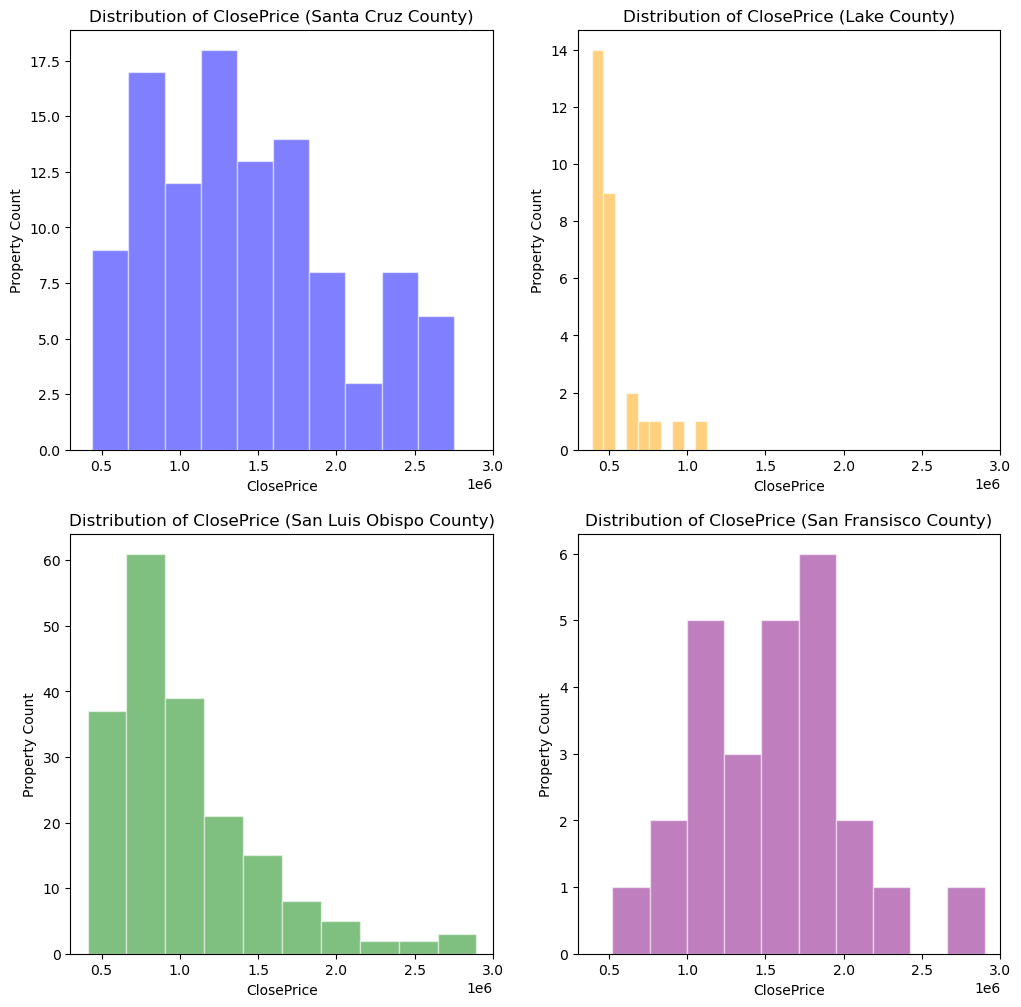

In [74]:
# Create distribution of ClosePrice for the top four worst performing counties: Santa Cruz, Lake, San Luis Obispo, San Fransisco

#bins = [0, 650000, 890000, 1350000, 3156640]
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

axes[0,0].hist(testing[testing["CountyOrParish"] == "Santa Cruz"]["ClosePrice"], alpha=0.5, color="blue", edgecolor="white")
axes[0,0].set_title("Distribution of ClosePrice (Santa Cruz County)")
axes[0,0].set_xlabel("ClosePrice")
axes[0,0].set_xlim(300000, 3000000)
axes[0,0].set_ylabel("Property Count")

axes[0,1].hist(testing[testing["CountyOrParish"] == "Lake"]["ClosePrice"], alpha=0.5, color="orange", edgecolor="white")
axes[0,1].set_title("Distribution of ClosePrice (Lake County)")
axes[0,1].set_xlabel("ClosePrice")
axes[0,1].set_xlim(300000, 3000000)
axes[0,1].set_ylabel("Property Count")

axes[1,0].hist(testing[testing["CountyOrParish"] == "San Luis Obispo"]["ClosePrice"], alpha=0.5, color="green", edgecolor="white")
axes[1,0].set_title("Distribution of ClosePrice (San Luis Obispo County)")
axes[1,0].set_xlabel("ClosePrice")
axes[1,0].set_xlim(300000, 3000000)
axes[1,0].set_ylabel("Property Count")

axes[1,1].hist(testing[testing["CountyOrParish"] == "San Francisco"]["ClosePrice"], alpha=0.5,color="purple", edgecolor="white")
axes[1,1].set_title("Distribution of ClosePrice (San Fransisco County)")
axes[1,1].set_xlabel("ClosePrice")
axes[1,1].set_xlim(300000, 3000000)
axes[1,1].set_ylabel("Property Count")

It's apparent from these results that our model struggles with some counties more than others. The ones that repeatedly appear are Santa Cruz, Lake, San Luis Obispo, and San Fransisco. It's hard to say definitively why our models struggle with these counties. However, graphs of their ClosePrice distributions indicate that Santa Cruz, San Luis Obispo, and San Fransisco counties have a fairly high number of luxury homes (ClosePrice > 1.35 $*$ 1e6), which we know our model has more difficulty predicting accurately. Similarly, the model may not predict Lake county properties well because they are almost entirely concentrated in the below-average price range and have only a few samples. The best way to fix this problem would simply be to gather more datapoints in these areas.

## Summary

This investigation has yielded some very interesting results. For one, we have found that the most powerful feature for prediction in our models is PostalCode. This corroborates the famous real estate idea of "Location, Location, Location." PostalCode, and features that similarly encode location, have a very high predictive power. The second most important feature for prediction in our models is LivingArea. We've also found that our models perform worse when predicting luxury homes (ClosePrice above \$1,350,000). Likewise, the models seem to perform worse in counties with a high median ClosePrice, like San Fransisco and Santa Cruz. These errors are mostly caused by under-prediction of large ClosePrice values, in which the models predict a ClosePrice significantly smaller than the real value.